# Producion Agricola (Analisis Exploratorio de Datos)

Una vez realizados los ajustes pertinentes al conjunto de datos principal. Procedemos a realizar el analisis exploratorio de datos.
Donde conoceremos los datos y los iremos preparando para los futuroes modelos planteados.

**Observación** Una de las cosas distintivas con respecto a las etapas pasadas es que si nuestro problema lo requiere conectaremos nuestros datos principales con otras fuentes. Como veremos más adelante

In [2]:
from scripts.config import PRELOADS, DATA_DIR
import os
import pickle
import pandas as pd

# Notemos que ahora estamos obteniendo la información ya normalizada.
with open(PRELOADS['AGROPROD_2'], "rb") as preprocess: 
    dgsiap = pickle.load(preprocess)

dgsiap

Comenzamos con la carga de los conjuntos de datos de Producción Agricola de parte del DGSIAP.

In [3]:
dataset = [file.open(pars=[1, {"low_memory":False, "index_col":0}]) for file in dgsiap.branch]

Recordemos que en esta primera parte procuramos estimar la tasa de éxito de un cultivo en función del clima de la región. Evitando confundir con el rendimiento. La tasa de exito en un cultivo es el cociente entre las hectareas cosechadas y las hectarias sembradas. Para este analisis omitiremos las hectareas siniestradas.

Primero haremos conjunto de datos que considere todos los años.

In [29]:
prodagro = dataset[0]

Como EDA de muestra usaremos un cultivo arbitrario.

In [30]:
# Buscamos todos los cultivos.
crops = prodagro['Nomcultivo'].unique().tolist()
crop_s = crops[20]
crop_s

'Uva'

Tomando la Uva como ejemplo. Vemos los estados que la cosechan 

In [31]:
prod_crop = prodagro[prodagro['Nomcultivo']==crop_s]
print(f"Estados que siembran {crop_s}", prod_crop['Nomestado'].unique().tolist())
crop_rate = prod_crop['Cosechada'].sum() / prod_crop['Sembrada'].sum()
print(f"Tasa de Exito en México de {crop_s}: {crop_rate*100:2f}")

Estados que siembran Uva ['Aguascalientes', 'Baja California', 'Baja California Sur', 'Coahuila', 'Chihuahua', 'Durango', 'Guanajuato', 'Jalisco', 'Nayarit', 'Nuevo León', 'Puebla', 'Querétaro', 'San Luis Potosí', 'Sinaloa', 'Sonora', 'Zacatecas']
Tasa de Exito en México de Uva: 99.078994


La uva tiene una tasa de exito en Mexico de aproximadamente 99.079%. Haremos lo mismo con por estado.

In [32]:
prod_crop_ent = prod_crop.groupby("Nomestado")[['Sembrada','Cosechada']].sum()
prod_crop_ent['TasaExito'] = prod_crop_ent['Cosechada'] / prod_crop_ent['Sembrada'] * 100
prod_crop_ent

,Sembrada,Cosechada,TasaExito
Nomestado,,,
Aguascalientes,1167.04,1102.04,94.430354
Baja California,4493.49,4488.49,99.888728
Baja California Sur,48.50,10.50,21.649485
Chihuahua,422.83,294.00,69.531490
Coahuila,767.50,676.50,88.143322
Durango,3.00,3.00,100.000000
Guanajuato,511.00,509.00,99.608611
Jalisco,1458.50,1458.50,100.000000
Nayarit,108.00,107.50,99.537037


In [33]:
prod_crop_ent['TasaExito'].mean()

np.float64(90.81786481103282)

Vemos que el porcentaje promedio es mucho menor al porcentaje nacional. Por lo tanto, el porcentaje nacional es una ponderación de los porcentajes estatales.


In [34]:
prod_crop_ent['Ponderado'] = prod_crop_ent['Sembrada'] / prod_crop['Sembrada'].sum() * 100
crop_top_prod = prod_crop_ent.sort_values(by="Ponderado",ascending=False)
print("Notemos que con solo los primeros 3 estados tenemos que México tiene una tasa de éxito de ",
      crop_top_prod.iloc[:3, 1].sum()/crop_top_prod.iloc[:3, 0].sum())
print("Los 29 estados faltantes generan un error de:", 
      crop_top_prod.iloc[:3, 1].sum()/crop_top_prod.iloc[:3, 0].sum() - crop_rate)
crop_top_prod


Notemos que con solo los primeros 3 estados tenemos que México tiene una tasa de éxito de  0.9998476236450313
Los 29 estados faltantes generan un error de: 0.009057680886727204


,Sembrada,Cosechada,TasaExito,Ponderado
Nomestado,,,,
Sonora,20388.00,20388.00,100.000000,53.561141
Zacatecas,7932.00,7932.00,100.000000,20.838089
Baja California,4493.49,4488.49,99.888728,11.804809
Jalisco,1458.50,1458.50,100.000000,3.831613
Aguascalientes,1167.04,1102.04,94.430354,3.065921
Coahuila,767.50,676.50,88.143322,2.016293
Querétaro,530.00,529.75,99.952830,1.392358
Guanajuato,511.00,509.00,99.608611,1.342444
Chihuahua,422.83,294.00,69.531490,1.110813


De esto vemos que Sonora, Zacatecas y Baja California representan más del 85% del éxito de los cultivos de Uva. Ahora veamos esto para el resto de cultivos.

In [39]:
def sucess_rate(crop, df):
    prod_crop = df[df['Nomcultivo']==crop]
    crop_rate = prod_crop['Cosechada'].sum() / prod_crop['Sembrada'].sum()
    return crop_rate


all_rate_crops = pd.DataFrame(index=crops, columns=['TasaExitoNacional'])
for crop in all_rate_crops.index:
    all_rate_crops.loc[crop, 'TasaExitoNacional'] = sucess_rate(crop, prodagro)


/tmp/ipykernel_8261/2263796466.py:3: RuntimeWarning: invalid value encountered in scalar divide
  crop_rate = prod_crop['Cosechada'].sum() / prod_crop['Sembrada'].sum()
/tmp/ipykernel_8261/2263796466.py:3: RuntimeWarning: invalid value encountered in scalar divide
  crop_rate = prod_crop['Cosechada'].sum() / prod_crop['Sembrada'].sum()


In [59]:
all_rate_crops[all_rate_crops['TasaExitoNacional']<0.5]
print(len(all_rate_crops[all_rate_crops['TasaExitoNacional']<0.5]) / len(crops) * 100)

2.6058631921824107


Vemos que durante 2025. Solo 2.6% de cultivos tuvieron menos del 50% de efectividad. Aplicando esto a todos los años veremos cuales han sido los mejores cultivos en México.

In [66]:
crop_history= pd.DataFrame(index=crops, columns=[f'{y}' for y in range(2003, 2026)])
for k, prodagro in enumerate(dataset):
    year = f"{2025-k}"
    for crop in crop_history.index:
        crop_history.loc[crop, f'{year}'] = sucess_rate(crop, prodagro)

crop_history

/tmp/ipykernel_8261/2263796466.py:3: RuntimeWarning: invalid value encountered in scalar divide
  crop_rate = prod_crop['Cosechada'].sum() / prod_crop['Sembrada'].sum()
/tmp/ipykernel_8261/2263796466.py:3: RuntimeWarning: invalid value encountered in scalar divide
  crop_rate = prod_crop['Cosechada'].sum() / prod_crop['Sembrada'].sum()
/tmp/ipykernel_8261/2263796466.py:3: RuntimeWarning: invalid value encountered in scalar divide
  crop_rate = prod_crop['Cosechada'].sum() / prod_crop['Sembrada'].sum()
/tmp/ipykernel_8261/2263796466.py:3: RuntimeWarning: invalid value encountered in scalar divide
  crop_rate = prod_crop['Cosechada'].sum() / prod_crop['Sembrada'].sum()
/tmp/ipykernel_8261/2263796466.py:3: RuntimeWarning: invalid value encountered in scalar divide
  crop_rate = prod_crop['Cosechada'].sum() / prod_crop['Sembrada'].sum()
/tmp/ipykernel_8261/2263796466.py:3: RuntimeWarning: invalid value encountered in scalar divide
  crop_rate = prod_crop['Cosechada'].sum() / prod_crop['Sem

,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Avena forrajera en verde,0.863373,0.960247,0.789375,0.985898,0.946323,0.971395,0.850804,0.902322,0.715493,0.93611,...,0.994826,0.991742,0.987971,0.975884,0.878272,0.99152,0.992849,0.7136,0.911567,0.993013
Brócoli,0.969776,0.989797,0.996538,0.97158,0.993488,0.984046,0.995836,0.99095,0.982809,0.98321,...,0.99569,0.998261,0.981809,1.0,0.999803,0.99819,0.999335,0.998754,0.998613,0.989817
Calabacita,0.97312,0.944095,0.97905,0.943678,0.967026,0.969646,0.981857,0.982953,0.810801,0.960055,...,0.984322,0.976347,0.992599,0.994565,0.98914,0.99689,0.997721,0.999574,0.997409,0.752371
Cebolla,0.954342,0.985378,0.989223,0.974955,0.988389,0.981394,0.975885,0.993567,0.968898,0.959278,...,0.981038,0.991613,0.99514,0.997659,0.996435,0.999958,0.99876,0.99845,0.998299,0.995355
Chile verde,0.922279,0.946053,0.908052,0.963274,0.938214,0.910489,0.965538,0.947562,0.913375,0.982386,...,0.98343,0.998903,0.990604,0.964314,0.986861,0.977506,0.987487,0.99416,0.994387,0.994689
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Ebo (janamargo o veza) grano,0.623333,1.0,0.96319,1.0,0.981221,0.159664,1.0,1.0,0.942478,0.989637,...,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,1.0,1.0
Malanga,1.0,1.0,0.0,1.0,NaN,NaN,NaN,0.84038,0.918919,0.60749,...,0.664062,0.779087,0.798387,1.0,NaN,NaN,1.0,1.0,1.0,1.0
Zapupe,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,0.993056,NaN,NaN,1.0,1.0,1.0,1.0
Saramuyo,0.950725,0.890244,0.889571,0.946667,0.953333,0.966216,1.0,0.993103,1.0,1.0,...,0.965909,1.0,1.0,0.960396,NaN,NaN,0.960396,0.80663,1.0,1.0


In [80]:
principal_crops = crop_history.isna().sum(axis=1).sort_values(ascending=False)
x = principal_crops[principal_crops==0].index.tolist()
x

['Avena forrajera en verde',
 'Brócoli',
 'Nopalitos',
 'Granada',
 'Durazno',
 'Alfalfa verde',
 'Frijol',
 'Zanahoria',
 'Tomate verde',
 'Tomate rojo (jitomate)',
 'Sorgo forrajero en verde',
 'Maíz grano',
 'Maíz forrajero en verde',
 'Chía',
 'Huauzontle',
 'Caña de azúcar fruta',
 'Zempoalxochitl',
 'Amaranto',
 'Romerito',
 'Tabaco',
 'Ajonjolí',
 'Tejocote',
 'Cacao',
 'Café cereza',
 'Berenjena',
 'Plátano',
 'Copra',
 'Caña de azúcar',
 'Arroz palay',
 'Piña',
 'Soya',
 'Papaya',
 'Melón',
 'Trigo grano',
 'Cebada grano',
 'Papa',
 'Garbanzo grano',
 'Cártamo',
 'Mango',
 'Sorgo grano',
 'Algodón hueso',
 'Zarzamora',
 'Toronja (pomelo)',
 'Frambuesa',
 'Alfalfa achicalada',
 'Pepino',
 'Avena grano',
 'Pera',
 'Sandía',
 'Mandarina',
 'Uva',
 'Nuez',
 'Chile seco',
 'Ajo',
 'Naranja',
 'Manzana',
 'Limón',
 'Guayaba',
 'Aguacate',
 'Elote',
 'Espárrago',
 'Lechuga',
 'Coliflor',
 'Tuna',
 'Agave',
 'Calabacita',
 'Fresa',
 'Chile verde',
 'Cebolla']

In [81]:
crop_history.loc[x]

,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Avena forrajera en verde,0.863373,0.960247,0.789375,0.985898,0.946323,0.971395,0.850804,0.902322,0.715493,0.93611,...,0.994826,0.991742,0.987971,0.975884,0.878272,0.99152,0.992849,0.7136,0.911567,0.993013
Brócoli,0.969776,0.989797,0.996538,0.97158,0.993488,0.984046,0.995836,0.99095,0.982809,0.98321,...,0.99569,0.998261,0.981809,1.0,0.999803,0.99819,0.999335,0.998754,0.998613,0.989817
Nopalitos,0.986509,0.980494,0.970975,0.990918,0.984266,0.985897,0.980654,0.978234,0.963218,0.971998,...,0.96886,0.948386,0.966928,0.978386,0.988384,0.988326,0.989951,0.984781,0.984253,0.982524
Granada,0.969729,0.935428,0.906122,0.990467,0.8,0.875109,0.871777,0.863471,0.828871,0.889265,...,0.892976,0.872799,0.877098,0.911985,0.908281,0.924814,0.90914,0.8583,0.852298,0.859862
Durazno,0.667536,0.81913,0.8386,0.90834,0.915513,0.884492,0.953152,0.931297,0.824092,0.766678,...,0.897994,0.817705,0.886273,0.884664,0.778183,0.928613,0.951976,0.940891,0.960956,0.967716
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Agave,0.079515,0.069047,0.072178,0.068845,0.086911,0.104817,0.092591,0.097791,0.119358,0.144421,...,0.196482,0.206811,0.207586,0.200707,0.198039,0.173593,0.184627,0.139036,0.135093,0.133412
Calabacita,0.97312,0.944095,0.97905,0.943678,0.967026,0.969646,0.981857,0.982953,0.810801,0.960055,...,0.984322,0.976347,0.992599,0.994565,0.98914,0.99689,0.997721,0.999574,0.997409,0.752371
Fresa,0.952056,0.978376,1.0,1.0,0.992675,0.993391,0.99965,0.961109,0.99644,0.95781,...,0.999915,0.999931,0.995989,0.97618,0.995252,0.99747,0.999925,0.997365,0.995122,0.989483
Chile verde,0.922279,0.946053,0.908052,0.963274,0.938214,0.910489,0.965538,0.947562,0.913375,0.982386,...,0.98343,0.998903,0.990604,0.964314,0.986861,0.977506,0.987487,0.99416,0.994387,0.994689


(0.0, 1.0)

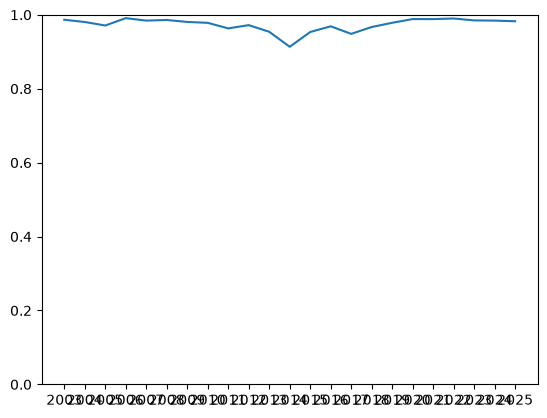

In [84]:
import matplotlib.pyplot as plt

plt.plot(crop_history.columns, crop_history.loc['Nopalitos'])
plt.ylim([0,1])